# Part B: Image Classification - Step 1: Preprocessing & Logistic Regression

Load and inspect image data (Flowers dataset), resize, normalize, extract flattened representations, and establish a baseline with Logistic Regression.

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, silhouette_score
from scipy.stats import mode
import random
import pandas as pd
import seaborn as sns
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-darkgrid')

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

print("Environment and directories are ready")

Environment and directories are ready!


Classes found (5): ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Total valid images inspected: 4317


/tmp/ipykernel_233553/2365367386.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_meta, x='class', order=CLASSES, palette='viridis', ax=axes[0])


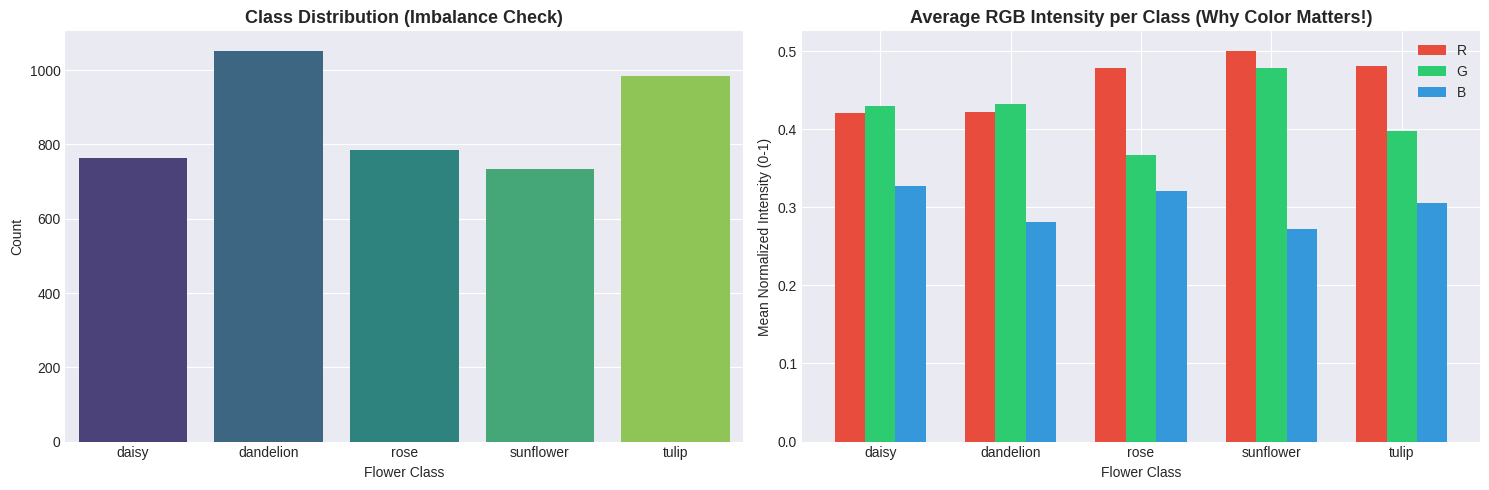

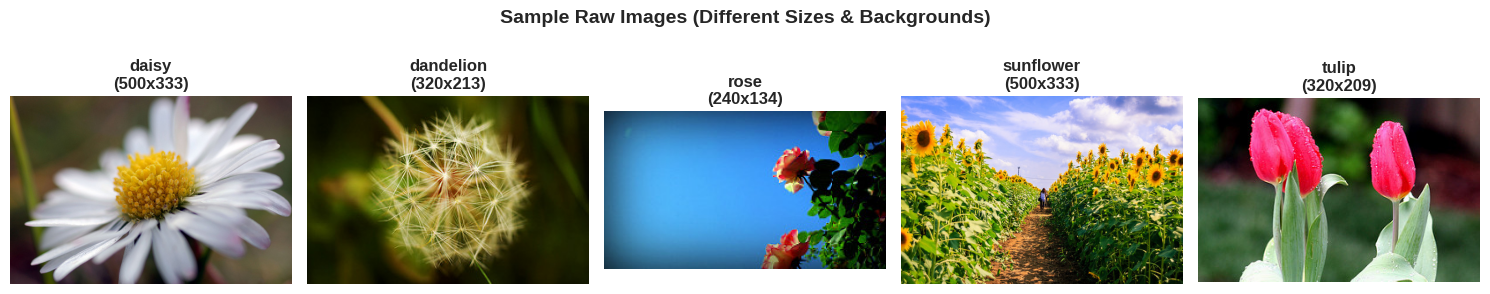

In [5]:
base_dir = "/mnt/Basic\\x20data\\x20partition/linux files/college projects/ML Project/Images/archive (1)"
data_dir = os.path.join(base_dir, "flowers")
if not os.path.exists(data_dir):
    data_dir = base_dir

CLASSES = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
print(f"Classes found ({len(CLASSES)}): {CLASSES}")

meta_records = []
for label_idx, cls in enumerate(CLASSES):
    cls_path = os.path.join(data_dir, cls)
    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        img = cv2.imread(img_path)
        if img is not None:
            h, w, _ = img.shape
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            mean_rgb = img_rgb.mean(axis=(0, 1)) / 255.0
            meta_records.append({
                'class': cls, 'label': label_idx, 'path': img_path,
                'width': w, 'height': h,
                'R': mean_rgb[0], 'G': mean_rgb[1], 'B': mean_rgb[2]
            })

df_meta = pd.DataFrame(meta_records)
print(f"Total valid images inspected: {len(df_meta)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df_meta, x='class', order=CLASSES, palette='viridis', ax=axes[0])
axes[0].set_title('Class Distribution (Imbalance Check)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Flower Class')
axes[0].set_ylabel('Count')

df_colors = df_meta.groupby('class')[['R', 'G', 'B']].mean().loc[CLASSES]
df_colors.plot(kind='bar', color=['#e74c3c', '#2ecc71', '#3498db'], ax=axes[1], width=0.7)
axes[1].set_title('Average RGB Intensity per Class (Why Color Matters!)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Flower Class')
axes[1].set_ylabel('Mean Normalized Intensity (0-1)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for idx, cls in enumerate(CLASSES):
    sample_path = df_meta[df_meta['class'] == cls]['path'].iloc[0]
    img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img)
    axes[idx].set_title(f"{cls}\n({img.shape[1]}x{img.shape[0]})", fontweight='bold')
    axes[idx].axis('off')
plt.suptitle("Sample Raw Images (Different Sizes & Backgrounds)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [13]:
from skimage.feature import hog
import skimage.feature as skf

IMG_SIZE = 128

def extract_image_features(img_bgr):
    img_resized = cv2.resize(img_bgr, (IMG_SIZE, IMG_SIZE))

    img_hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    hist_hsv = cv2.calcHist([img_hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist_hsv, hist_hsv) # Normalization للـ Histogram
    color_features = hist_hsv.flatten()
    
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    img_gray_norm = img_gray.astype('float32') / 255.0 # Pixel Normalization (0 to 1)
    hog_features = hog(
        img_gray_norm, orientations=9, pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False
    )
    
    img_small_norm = cv2.resize(img_resized, (32, 32)).astype('float32') / 255.0
    raw_pixel_features = img_small_norm.flatten()
    
    return np.hstack([color_features, hog_features, raw_pixel_features])

print("Extracting features (Resize + Normalize + HSV Color Hist + HOG)...")
X_list, y_list = [], []

for row in df_meta.itertuples():
    img = cv2.imread(row.path)
    if img is not None:
        features = extract_image_features(img)
        X_list.append(features)
        y_list.append(row.label)

X_all = np.array(X_list, dtype=np.float32)
y_all = np.array(y_list, dtype=np.int64)

print(f"Feature extraction complete! Matrix shape: {X_all.shape}")

Extracting features (Resize + Normalize + HSV Color Hist + HOG)...
Feature extraction complete! Matrix shape: (4317, 5348)


In [14]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=SEED, stratify=y_all
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Split sizes -> Train: {len(X_train)} (70%), Val: {len(X_val)} (15%), Test: {len(X_test)} (15%)")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=150, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

explained_var = np.sum(pca.explained_variance_ratio_) * 100
print(f"PCA Reduced Shape: {X_train_pca.shape} (Preserving {explained_var:.2f}% of variance)")

Split sizes -> Train: 3021 (70%), Val: 648 (15%), Test: 648 (15%)
PCA Reduced Shape: (3021, 150) (Preserving 66.85% of variance)


NumPy LR (learning_rate=0.005) -> Validation Accuracy: 0.5895
NumPy LR (learning_rate=0.01) -> Validation Accuracy: 0.5895
NumPy LR (learning_rate=0.05) -> Validation Accuracy: 0.5401

Best NumPy Logistic Regression (lr=0.005) Validation Accuracy: 0.5895


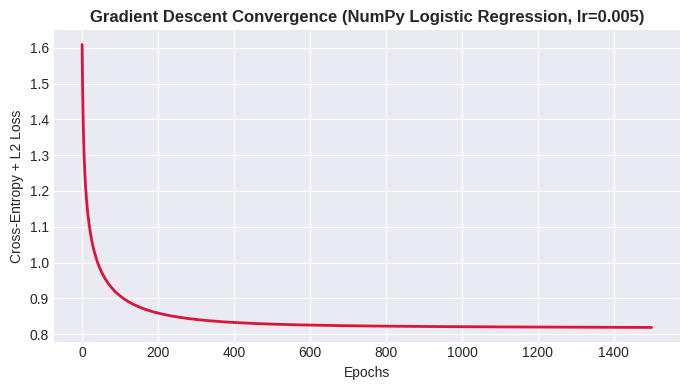

In [15]:
class NumpyLogisticRegression:
    """
    Multinomial Logistic Regression (Softmax Regression) implemented from scratch using NumPy only.
    Uses Batch Gradient Descent with L2 Regularization.
    """
    def __init__(self, learning_rate=0.01, epochs=1500, reg_lambda=0.05):
        self.lr = learning_rate
        self.epochs = epochs
        self.reg_lambda = reg_lambda
        self.W = None
        self.b = None
        self.loss_history = []

    def _softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _one_hot(self, y, num_classes):
        one_hot = np.zeros((y.size, num_classes))
        one_hot[np.arange(y.size), y] = 1
        return one_hot

    def fit(self, X, y):
        n_samples, n_features = X.shape
        n_classes = len(np.unique(y))
        
        self.W = np.zeros((n_features, n_classes))
        self.b = np.zeros(n_classes)
        y_encoded = self._one_hot(y, n_classes)

        for epoch in range(self.epochs):
            # 1. Forward Pass
            logits = np.dot(X, self.W) + self.b
            probs = self._softmax(logits)

            ce_loss = -np.mean(np.sum(y_encoded * np.log(probs + 1e-12), axis=1))
            l2_loss = (self.reg_lambda / 2) * np.sum(self.W ** 2)
            self.loss_history.append(ce_loss + l2_loss)

            # 3. Backward Pass (Gradients)
            error = probs - y_encoded
            dW = (1 / n_samples) * np.dot(X.T, error) + (self.reg_lambda * self.W)
            db = (1 / n_samples) * np.sum(error, axis=0)

            # 4. Update Weights
            self.W -= self.lr * dW
            self.b -= self.lr * db

        return self

    def predict_proba(self, X):
        logits = np.dot(X, self.W) + self.b
        return self._softmax(logits)

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

best_np_lr, best_np_acc, best_lr_val = None, 0, None
for lr_val in [0.005, 0.01, 0.05]:
    model_np = NumpyLogisticRegression(learning_rate=lr_val, epochs=1500, reg_lambda=0.05)
    model_np.fit(X_train_pca, y_train)
    val_preds = model_np.predict(X_val_pca)
    acc = accuracy_score(y_val, val_preds)
    print(f"NumPy LR (learning_rate={lr_val}) -> Validation Accuracy: {acc:.4f}")
    if acc > best_np_acc:
        best_np_acc = acc
        best_np_lr = model_np
        best_lr_val = lr_val

print(f"\nBest NumPy Logistic Regression (lr={best_lr_val}) Validation Accuracy: {best_np_acc:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(best_np_lr.loss_history, color='crimson', linewidth=2)
plt.title(f"Gradient Descent Convergence (NumPy Logistic Regression, lr={best_lr_val})", fontweight='bold')
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy + L2 Loss")
plt.tight_layout()
plt.show()

In [16]:
c_values = [0.001, 0.01, 0.05, 0.1, 1.0, 10.0]
val_accuracies = []
best_sk_lr, best_sk_acc, best_c = None, 0, None

for c in c_values:
    sk_lr = LogisticRegression(C=c, max_iter=1000, random_state=SEED)
    sk_lr.fit(X_train_pca, y_train)
    val_preds = sk_lr.predict(X_val_pca)
    acc = accuracy_score(y_val, val_preds)
    val_accuracies.append(acc)
    print(f"Sklearn LogisticRegression (C={c}) -> Validation Accuracy: {acc:.4f}")
    
    if acc > best_sk_acc:
        best_sk_acc = acc
        best_sk_lr = sk_lr
        best_c = c

print("-" * 60)
print(f"Best Sklearn LR (C={best_c}) Validation Accuracy : {best_sk_acc:.4f}")
print(f"Best NumPy LR (From Scratch) Validation Accuracy: {best_np_acc:.4f}")
print(f"Difference between Sklearn & NumPy on Val Set   : {abs(best_sk_acc - best_np_acc):.4f}")

Sklearn LogisticRegression (C=0.001) -> Validation Accuracy: 0.6096
Sklearn LogisticRegression (C=0.01) -> Validation Accuracy: 0.5880
Sklearn LogisticRegression (C=0.05) -> Validation Accuracy: 0.5880
Sklearn LogisticRegression (C=0.1) -> Validation Accuracy: 0.5895
Sklearn LogisticRegression (C=1.0) -> Validation Accuracy: 0.5895
Sklearn LogisticRegression (C=10.0) -> Validation Accuracy: 0.5895
------------------------------------------------------------
Best Sklearn LR (C=0.001) Validation Accuracy : 0.6096
Best NumPy LR (From Scratch) Validation Accuracy: 0.5895
Difference between Sklearn & NumPy on Val Set   : 0.0201


In [ ]:
np.savez_compressed(
    "../data/processed/flowers_pca_splits.npz",
    X_train=X_train_pca, y_train=y_train,
    X_val=X_val_pca, y_val=y_val,
    X_test=X_test_pca, y_test=y_test,
    classes=np.array(CLASSES)
)

joblib.dump(scaler, "../models/image_scaler.joblib")
joblib.dump(pca, "../models/image_pca.joblib")
joblib.dump(best_sk_lr, "../models/image_lr_sklearn.joblib")
joblib.dump(best_np_lr, "../models/image_lr_numpy.joblib")

print("All processed splits and Step 1 models saved successfully!")